[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_6_Conglomerados.ipynb)

# Fase 6. Análisis de conglomerados

En esta fase busco grupos de compuestos con perfiles fisicoquímicos parecidos. Para construir los conglomerados uso solo las variables seleccionadas y el conjunto de entrenamiento. No incluyo MolLogP ni la etiqueta DILI en la formación de los grupos; después describo los conglomerados según su composición DILI.

## 6.1. Lectura de los datos

In [1]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /workspace/scratch/b597cb51ba0f/run_outputs/datos_dili
Descriptores numéricos disponibles: 218


## 6.2. Selección de variables y número de grupos

Estandarizo cinco descriptores usando parámetros aprendidos con train. Comparo soluciones de dos a seis grupos mediante WCSS y coeficiente de silueta.

,k,WCSS,silueta
0,2,1335.265,0.937
1,3,791.243,0.713
2,4,609.158,0.560
3,5,440.233,0.563
4,6,363.774,0.336


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


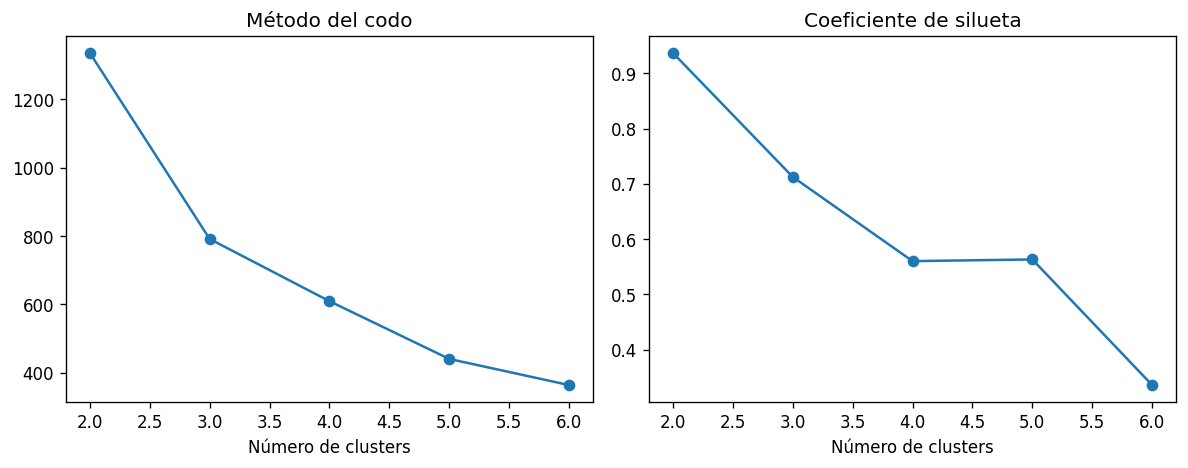

In [2]:
import matplotlib.pyplot as plt  # Dibujo la evaluación del modelo.
# Importo las herramientas para estandarizar y agrupar compuestos.
from sklearn.impute import SimpleImputer  # Completo valores ausentes si aparecen.
from sklearn.preprocessing import StandardScaler  # Pongo las variables en escalas comparables.
from sklearn.cluster import KMeans  # Ajusto los conglomerados.
from sklearn.metrics import silhouette_score  # Comparo cohesión y separación.

# Selecciono cinco propiedades fisicoquímicas para formar los grupos.
variables_cluster = ['MolWt', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds']  # Defino las variables del análisis.
variables_cluster = [variable for variable in variables_cluster if variable in train_df.columns]  # Confirmo que estén disponibles.

# Aprendo imputación y escalado usando solamente train.
imputador = SimpleImputer(strategy='median')  # Creo imputación por mediana.
imputador.fit(train_df[variables_cluster])  # Aprendo las medianas en train.
X_imp = imputador.transform(train_df[variables_cluster])  # Transformo las variables de train.
escalador = StandardScaler()  # Creo el escalador.
X_train = escalador.fit_transform(X_imp)  # Ajusto y transformo train.

# Comparo entre dos y seis conglomerados con las métricas solicitadas.
resultados = []  # Creo una lista para guardar las métricas.
for k in range(2, 7):  # Pruebo distintos números de grupos.
    ajuste = KMeans(n_clusters=k, random_state=42, n_init=20)  # Defino el algoritmo reproducible.
    etiquetas = ajuste.fit_predict(X_train)  # Ajusto grupos y asigno cada compuesto.
    resultados.append({'k': k, 'WCSS': ajuste.inertia_, 'silueta': silhouette_score(X_train, etiquetas)})  # Guardo criterios de calidad.
tabla_k = pd.DataFrame(resultados)  # Creo una tabla de comparación.
display(tabla_k.round(3))  # Muestro las métricas.

# Represento el codo y la silueta para apoyar la elección de k.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # Creo dos paneles.
axes[0].plot(tabla_k['k'], tabla_k['WCSS'], marker='o')  # Dibujo WCSS frente a k.
axes[0].set_title('Método del codo')  # Titulo el primer panel.
axes[0].set_xlabel('Número de clusters')  # Etiqueto el eje horizontal.
axes[1].plot(tabla_k['k'], tabla_k['silueta'], marker='o')  # Dibujo silueta frente a k.
axes[1].set_title('Coeficiente de silueta')  # Titulo el segundo panel.
axes[1].set_xlabel('Número de clusters')  # Etiqueto el eje horizontal.
plt.tight_layout()  # Ajusto los paneles.
plt.show()  # Muestro ambos gráficos.


## 6.3. Perfil de conglomerados

Selecciono el número de grupos con la silueta como referencia y reviso el método del codo. Calculo tamaños y centroides en unidades originales. Finalmente describo la proporción DILI de cada grupo, sin haber utilizado la etiqueta para formarlo.

In [3]:
# Selecciono el número de grupos con mayor silueta entre los valores probados.
k_final = int(tabla_k.loc[tabla_k['silueta'].idxmax(), 'k'])  # Elijo k con mayor silueta.
modelo_cluster = KMeans(n_clusters=k_final, random_state=42, n_init=20)  # Creo el modelo final.
clusters_train = modelo_cluster.fit_predict(X_train)  # Ajusto el modelo y asigno grupos.
print('Número de clusters elegido:', k_final)  # Informo la elección.

# Añado la etiqueta de cluster al conjunto de entrenamiento para describir los grupos.
train_cluster = train_df.copy()  # Copio los registros de entrenamiento.
train_cluster['cluster'] = clusters_train  # Añado la asignación de conglomerado.
tamano = train_cluster['cluster'].value_counts().sort_index().to_frame('n')  # Cuento el tamaño de cada grupo.
tamano['porcentaje'] = (100 * tamano['n'] / len(train_cluster)).round(1)  # Calculo su porcentaje.
display(tamano)  # Muestro tamaños y proporciones.

# Expreso los centroides en las unidades originales de los descriptores.
centroides_originales = escalador.inverse_transform(modelo_cluster.cluster_centers_)  # Deshago la estandarización.
centroides = pd.DataFrame(centroides_originales, columns=variables_cluster)  # Organizo los centroides.
display(centroides.round(2))  # Muestro el perfil medio de cada grupo.

# Uso DILI solo después de formar los grupos para describir su composición.
composicion_dili = pd.crosstab(train_cluster['cluster'], train_cluster['DILI'], normalize='index').round(3)  # Calculo proporción por clase dentro de cada grupo.
display(composicion_dili.rename(columns={0: 'DILI negativa', 1: 'DILI positiva'}))  # Muestro la distribución de etiquetas.


Número de clusters elegido: 2


,n,porcentaje
cluster,,
0,935,98.9
1,10,1.1


,MolWt,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds
0,379.57,95.11,2.31,5.25,5.38
1,4061.54,1720.42,59.60,57.90,118.70


DILI,DILI negativa,DILI positiva
cluster,,
0,0.375,0.625
1,1.000,0.000


## Interpretación

Describo cada conglomerado por su tamaño y los valores medios de los descriptores. Comparo después su proporción de DILI positiva. La etiqueta sirve para interpretar los perfiles obtenidos, no para decidir la asignación del grupo. La silueta y el método del codo orientan la selección, pero no garantizan que exista una única segmentación correcta.